# 04. Autoencoder: 8차원 입력 → 2차원 latent → 8차원 재구성
`04_autoencoder.py`의 실제 코드를 실행해 정상 합성 시계열에서 만든 8차원 벡터를 압축하고, 검증 입력의 재구성 MSE를 기록합니다.

TODO B04의 `loss = nn.MSELoss()(reconstructed, x)`는 입력 자체를 정답으로 비교하므로 요구사항에 맞습니다.

## 0. 작업 전 준비사항
PyTorch, pandas, matplotlib이 설치된 커널에서 **Run All**로 실행합니다. CPU와 기존 `series.csv`를 사용하며 다운로드는 필요하지 않습니다.

원본 스크립트를 실행해 40 epoch 학습한 결과를 읽습니다. Python 파일은 수정하지 않으며, 노트북의 표와 그림은 `20261103/01_기본필수/docs/outputs`에 저장합니다. 커널 재시작 후에는 첫 셀부터 다시 실행합니다.

In [1]:
%matplotlib inline
from pathlib import Path
import runpy
import torch
from torch import nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
day_root = next((candidate for parent in (cwd, *cwd.parents)
                 for candidate in (parent / "20261103", parent)
                 if (candidate / "01_기본필수" / "04_autoencoder.py").is_file()), None)
if day_root is None:
    raise FileNotFoundError("이 저장소 안에서 실행하세요.")
out = day_root / "01_기본필수" / "docs" / "outputs"
out.mkdir(parents=True, exist_ok=True)
state = runpy.run_path(str(day_root / "01_기본필수" / "04_autoencoder.py"))
x, v, model, latent = (state[name] for name in ["x", "v", "model", "latent"])
print(model)

train: (53, 8) valid: (13, 8)
latent / 복원: (13, 2) (13, 8)
valid MSE: 0.056042
Sequential(
  (0): Linear(in_features=8, out_features=2, bias=True)
  (1): Tanh()
  (2): Linear(in_features=2, out_features=8, bias=True)
)


## 1. 정상 시계열을 8차원 벡터로 만들기
CSV를 시간순 train 60개·valid 20개로 나눈 뒤 각각의 구간 안에서 길이 8의 window를 만듭니다. test 20개는 모델에 전달하지 않습니다.

```python
x = train.unfold(0, 8, 1).contiguous()
v = valid.unfold(0, 8, 1).contiguous()
```

| 자료 | 원관측 수 | window 수 | 입력 shape |
| --- | --- | --- | --- |
| train | 60 | `60-8+1=53` | `(53,8)` |
| valid | 20 | `20-8+1=13` | `(13,8)` |

여기서 8차원은 서로 다른 센서 8개가 아니라 **연속된 관측값 8개**를 한 벡터에 담은 것입니다. `unfold(0,8,1)`은 시작점을 한 칸씩 이동하므로 인접 window는 관측 7개를 공유합니다. 시간 구간을 먼저 분리했으므로 train·valid 경계를 넘는 window는 없습니다.

`unfold()`는 겹치는 뷰를 만들 수 있습니다. `.contiguous()`는 메모리에 연속적으로 배치된 텐서를 준비하며, 시점 순서를 바꾸거나 정규화하는 연산은 아닙니다. 이 MLP Autoencoder는 2차원 `[자료 수, 특성 수]` 입력을 받으므로 LSTM처럼 별도 특성 축을 추가하지 않습니다.

In [2]:
assert x.shape == (53,8)
assert v.shape == (13,8)
assert torch.equal(x[0], state["train"][:8])
assert torch.equal(v[0], state["valid"][:8])
print("첫 train window:", x[0].tolist())
print("첫 valid window:", v[0].tolist())
print("연속 메모리 여부:", x.is_contiguous(), v.is_contiguous())

첫 train window: [0.15000000596046448, 0.3775995969772339, 0.5924383401870728, 0.7831473350524902, 0.9395929574966431, 1.0534108877182007, 1.1184474229812622, 1.1310842037200928]
첫 valid window: [0.8781283497810364, 0.9384316205978394, 0.9466511607170105, 0.9028311371803284, 0.8097675442695618, 0.672858476638794, 0.4998171031475067, 0.30026325583457947]
연속 메모리 여부: True True


## 2. Encoder와 Decoder의 역할
```python
model = nn.Sequential(
    nn.Linear(8, 2),  # Encoder: 8 → 2
    nn.Tanh(),       # latent를 비선형 변환
    nn.Linear(2, 8), # Decoder: 2 → 8
)
```

Encoder `model[:2]`는 Linear와 Tanh를 포함하여 `(B,8) → (B,2)`로 압축합니다. Tanh 출력은 -1~1 범위에 놓입니다. Decoder `model[2:]`는 latent로부터 `(B,8)`을 복원하며 마지막 Linear 뒤에 별도 활성화는 없습니다.

2차원 latent는 학습된 압축 좌표이며 두 좌표가 정해진 물리적 의미나 클래스 확률을 가진 것은 아닙니다. 차원 수가 8에서 2로 줄어들어도 파일 크기 1/4이나 무손실 복원을 보장하지 않습니다. 모델 가중치도 필요하며 작은 latent로 표현하기 어려운 정보가 손실될 수 있습니다.

파라미터는 Encoder `8×2+2=18`, Decoder `2×8+8=24`로 총 42개입니다.

## 3. 입력 자체를 target으로 40 epoch 학습
```python
optimizer.zero_grad()
reconstructed = model(x)
loss = nn.MSELoss()(reconstructed, x)
loss.backward()
optimizer.step()
```

각 epoch에서 train window 전체를 한 배치로 사용하고 Adam(lr=0.03)으로 한 번 갱신하므로 총 40번의 optimizer step을 수행합니다. 모델은 생성 직후 기본 train 모드입니다.

Autoencoder의 target은 입력 x 그 자체입니다. 정상 자료를 모두 0으로 바꾸는 과제가 아니며 클래스 라벨도 필요하지 않습니다. 이전 LSTM 다음 값 예측은 **입력 뒤의 미래 관측값**이 target인 반면, 이번 과제는 **입력 8개와 같은 값**을 복원합니다.

MSELoss의 기본 reduction은 mean입니다. train 손실은 모든 53×8개 원소의 제곱오차 평균입니다. 검증에서는 model.eval()과 torch.inference_mode()로 가중치 갱신 없이 valid 13×8개 원소의 평균 오차를 계산합니다. 최적 epoch 선택 코드는 없으므로 결과는 40 epoch 후 모델의 값입니다.

In [3]:
model.eval()
with torch.inference_mode():
    checked_latent = model[:2](v)
    restored = model[2:](checked_latent)
    direct_restored = model(v)
    squared_error = (restored-v).square()
    per_window_mse = squared_error.mean(dim=1)
    valid_mse = squared_error.mean().item()
    train_mse = nn.MSELoss()(model(x), x).item()
assert checked_latent.shape == (13,2)
assert restored.shape == v.shape == (13,8)
assert torch.allclose(latent, checked_latent)
assert torch.allclose(restored, direct_restored)
assert np.isclose(valid_mse, state["error"])
assert np.isclose(valid_mse, per_window_mse.mean().item())
assert sum(p.numel() for p in model.parameters()) == 42
print("입력:", tuple(v.shape))
print("latent:", tuple(checked_latent.shape))
print("재구성:", tuple(restored.shape))
print("40 epoch 후 train MSE:", f"{train_mse:.6f}")
print("valid MSE:", f"{valid_mse:.6f}")
summary = pd.DataFrame({"split": ["train", "valid"], "windows": [len(x), len(v)],
                        "input_dimensions": [8,8], "latent_dimensions": [2,2],
                        "epochs": [40,40], "mse": [train_mse,valid_mse]})
summary.to_csv(out / "autoencoder_mse_summary.csv", index=False)
records = pd.DataFrame({"valid_window": range(len(v)),
                        "latent_0": checked_latent[:,0].numpy(),
                        "latent_1": checked_latent[:,1].numpy(),
                        "reconstruction_mse": per_window_mse.numpy()})
records.to_csv(out / "autoencoder_latent_errors.csv", index=False)
print(records.round(6).to_string(index=False))

입력: (13, 8)
latent: (13, 2)
재구성: (13, 8)
40 epoch 후 train MSE: 0.076653
valid MSE: 0.056042
 valid_window  latent_0  latent_1  reconstruction_mse
            0 -0.000199 -0.970968            0.078772
            1 -0.238468 -0.948393            0.080074
            2 -0.422246 -0.890008            0.084355
            3 -0.544786 -0.739939            0.085604
            4 -0.614480 -0.402789            0.061808
            5 -0.641195  0.118578            0.053085
            6 -0.629646  0.576894            0.080631
            7 -0.577624  0.820781            0.064290
            8 -0.476624  0.920998            0.025750
            9 -0.316090  0.959734            0.007907
           10 -0.094696  0.974790            0.016036
           11  0.164631  0.979924            0.036706
           12  0.415586  0.979320            0.053523


## 4. 2차원 latent와 원본·복원 결과 시각화
latent 산점도의 색은 valid window 시작 인덱스입니다. 인접 window가 7개 관측을 공유하므로 가까운 좌표가 나타날 수 있지만, 독립된 클래스 군집으로 해석하지 않습니다.

복원 그래프는 대표 valid window 3개의 원본 관측 8개와 재구성 값을 보여 줍니다. 막대그래프는 각 window의 8개 특성에 대한 MSE입니다.

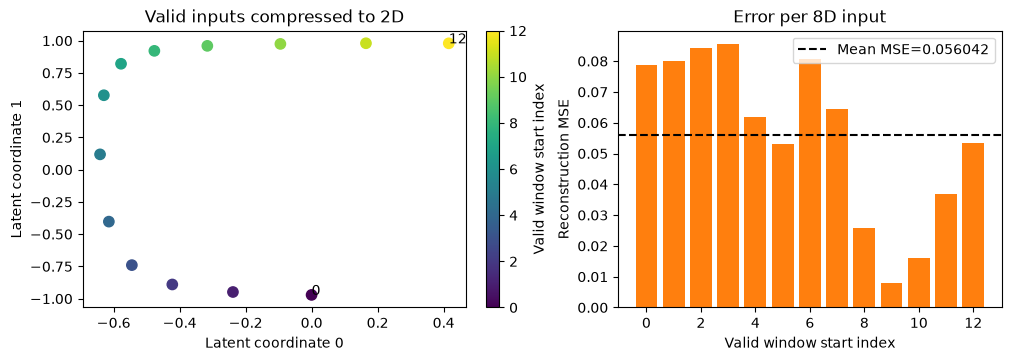

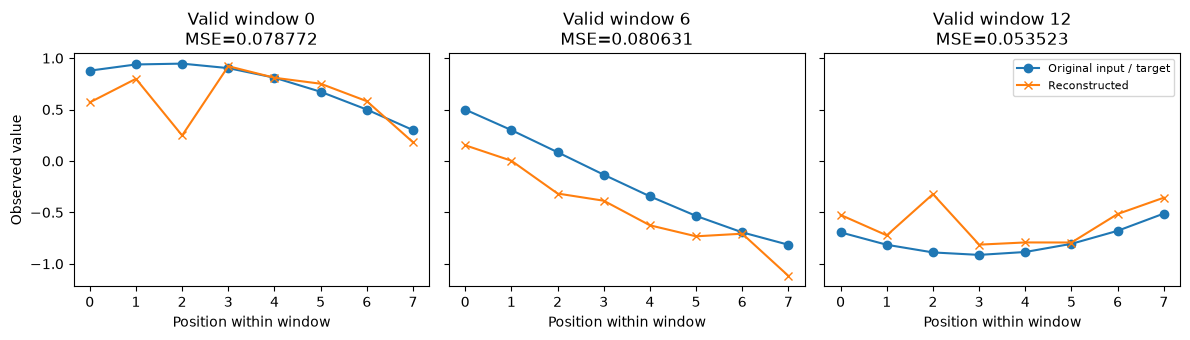

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10,3.5), constrained_layout=True)
scatter = axes[0].scatter(checked_latent[:,0].numpy(), checked_latent[:,1].numpy(),
                          c=np.arange(len(v)), cmap="viridis", s=55)
for i in [0, len(v)-1]:
    axes[0].annotate(str(i), (checked_latent[i,0].item(),checked_latent[i,1].item()))
axes[0].set_xlabel("Latent coordinate 0")
axes[0].set_ylabel("Latent coordinate 1")
axes[0].set_title("Valid inputs compressed to 2D")
fig.colorbar(scatter, ax=axes[0], label="Valid window start index")
axes[1].bar(range(len(v)), per_window_mse.numpy(), color="tab:orange")
axes[1].axhline(valid_mse, linestyle="--", color="black", label=f"Mean MSE={valid_mse:.6f}")
axes[1].set_xlabel("Valid window start index")
axes[1].set_ylabel("Reconstruction MSE")
axes[1].set_title("Error per 8D input")
axes[1].legend()
fig.savefig(out / "autoencoder_latent_mse.png", dpi=140)
plt.show()
plt.close(fig)

indices = [0, len(v)//2, len(v)-1]
fig, axes = plt.subplots(1, 3, figsize=(12,3.5), sharey=True)
for ax, i in zip(axes, indices):
    ax.plot(range(8), v[i].numpy(), marker="o", label="Original input / target")
    ax.plot(range(8), restored[i].numpy(), marker="x", label="Reconstructed")
    ax.set_title(f"Valid window {i}\nMSE={per_window_mse[i].item():.6f}")
    ax.set_xlabel("Position within window")
    ax.set_xticks(range(8))
axes[0].set_ylabel("Observed value")
axes[-1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(out / "autoencoder_reconstruction.png", dpi=140)
plt.show()
plt.close(fig)
comparison = pd.DataFrame({"valid_window": np.repeat(np.arange(len(v)),8),
                           "position": np.tile(np.arange(8),len(v)),
                           "original": v.numpy().reshape(-1),
                           "reconstructed": restored.numpy().reshape(-1),
                           "squared_error": squared_error.numpy().reshape(-1)})
comparison.to_csv(out / "autoencoder_reconstruction.csv", index=False)

## 5. 결과 해석 및 추가 실험
기본 실행의 valid MSE는 약 **0.056042**입니다. 입력 `(13,8)`이 latent `(13,2)`로 압축되고 다시 `(13,8)`로 복원됨을 확인했습니다. 자료별 MSE의 평균이 전체 valid MSE와 같은지도 검증했습니다.

작은 latent는 재구성 오차 0을 보장하지 않습니다. 압축 차원, 모델 구조, 학습 횟수·학습률과 데이터 분포가 복원 결과에 영향을 줍니다. 이 값은 간단한 정상 합성 시계열의 소표본 실험 결과입니다. 중첩 window 13개를 서로 완전히 독립된 원관측 104개처럼 해석하지 않습니다.

### 높은 재구성 오차가 무조건 이상인가요?
그렇지 않습니다. 정상 자료라도 학습 부족, 압축 손실, 잡음, 분포 변화 때문에 오차가 높을 수 있고, 이상 자료가 잘 복원되는 경우도 있을 수 있습니다. 이 실습에는 이상 라벨·판정 임계값·이상탐지 평가가 없습니다. MSE만으로 정상·이상 판정을 확정하지 않습니다.

### 직접 확인해 볼 내용
- latent 차원을 1·2·4로 바꾸고 동일한 split과 seed, 학습 조건에서 valid MSE를 비교합니다.
- 학습 횟수를 늘려 train MSE 감소와 valid MSE 변화가 일치하는지 확인합니다.
- 모델 선택에 valid를 사용한 뒤 최종 성능은 별도 test로 평가합니다. 현재 노트북은 test를 사용하지 않습니다.

### 자주 하는 실수 점검
- target을 0이 아니라 입력 자체로 사용했는가?
- train과 valid의 원래 시간 구간을 먼저 나눴는가?
- 원본과 재구성 shape가 같은가?
- latent를 클래스 확률이나 원래 관측값 두 개로 해석하지 않았는가?
- 재구성 오차를 다음 값 예측 오차나 이상 판정으로 혼동하지 않았는가?